# Continual learning + human in the loop: champion vs challenger (Milestone 4, Q1.4 and Q2.4)

**Question this notebook answers:** *when the data drifts, when should the forecaster be retrained, and how does a
human make that decision safer?*

**The strategy (champion vs challenger).** The deployed model is the **champion**. Every day we score its forecasts
against what really happened (the true occupancy is known 4 hours later). When the monitoring sees a problem, a new
model, the **challenger**, is trained on the last 6 months. It runs **in the shadow** for 7 days (it forecasts, but
its forecasts are not served), and it replaces the champion **only if it is at least 2% more accurate** on that week
(its interval is then recalibrated on that week).

**Where the human comes in.**
1. **Alert check:** when a retrain alert fires, the operator checks whether it is explained by known abnormal days
   (a holiday, a campus event). If so, the alert is dismissed and no challenger is trained.
2. **Shadow review (active learning):** each evening of the shadow week, the operator reviews the 2 forecasts where the
   champion and the challenger **disagree the most**, and tags each one *normal* or *abnormal*. Abnormal windows are left
   out of the comparison and out of future training.
3. **Sign-off:** the operator approves the promotion.

**How we simulate it.** JPL, from 26 April 2021: the real data with the Milestone 3 **Time-of-Use drift** (arrivals
2.5 h later). We replay 11 weeks **day by day** and compare 7 policies over 3 seeds.

## 1. Setup and settings

In [1]:
import contextlib
import io
import os
import sys
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset, WeightedRandomSampler

sys.path.insert(0, "src")
from models.train_neural import DLinear, fit, make_tensors, window_scale   # Milestone 2 model code

warnings.filterwarnings("ignore", category=ConvergenceWarning)

OUT = "outputs/continual"
os.makedirs(OUT, exist_ok=True)
SITE, CAPACITY, TZ = "jpl", 56.0, "America/Los_Angeles"
L, H = 672, 16                    # model window: 1 week of history, 4 hours ahead
DAY, WEEK = 96, 672               # in 15-minute steps

# Scenario
SHIFT_STEPS = 10                  # Time-of-Use drift from Milestone 3: arrivals 10 steps (2.5 h) later
REPLAY_DAYS = 77                  # 11 weeks, replayed day by day (stops before the July 2021 outage)

# Training (Milestone 2 hyperparameters, 6-month buffer from Part 1)
BUFFER_DAYS, CALIB_DAYS = 182, 7
HALF_LIFE_DAYS = 14.0
EPOCHS, PATIENCE, LR, BATCH = 30, 5, 1e-3, 256

# Monitoring and triggers (thresholds from the Milestone 3 monitoring notebooks)
DEGRADE = 1.25                    # 7-day MAE above 1.25 x the champion's own reference MAE ...
NAIVE_SLO = 0.80                  # ... or above 0.80 x the seasonal-naive MAE ...
STREAK = 3                        # ... for 3 days in a row
COVERAGE_BAND = (0.75, 0.85)      # recalibrate the interval when the 7-day coverage leaves this band
PSI_ALERT = 0.25                  # data drift vs the champion's own training buffer, 2 weeks in a row
MAX_AGE_DAYS = 56                 # safety net: a champion older than 8 weeks gets a challenger

# Champion vs challenger
SHADOW_DAYS = 7
MARGIN = 0.98                     # promote only if challenger MAE <= 98% of champion MAE
COOLDOWN_DAYS = 7                 # after a decision, wait before the next challenger

# Human in the loop
REVIEWS_PER_DAY = 2               # shadow-week forecasts reviewed per evening
ERROR_RATE = 0.05                 # chance the operator tags a window wrongly
MINUTES = {"review": 3, "alert": 10, "signoff": 10}
SEEDS = [0, 1, 2]                 # training randomness and operator mistakes

/speed-scratch/j_elbeti/myconda/lib/python3.8/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Rebuild the occupancy series

The data file stores training examples (1 week of history → the next 4 hours), one every 15 minutes. To apply the
drift once, we turn them back into one table *time → cars plugged in* and cut new examples from it with `windows()`.

In [2]:
d = np.load(f"outputs/{SITE}_occupancy_data.npz")
timestamps = pd.to_datetime(d["timestamps"])
T = len(timestamps)
series = np.full(T, np.nan, dtype=np.float32)
calendar = np.full((T, d["train_X_cal"].shape[2]), np.nan, dtype=np.float32)
for split in ["train", "val", "test"]:
    o = d[f"{split}_origins"]
    target_steps = o[:, None] + np.arange(H)
    series[target_steps], calendar[target_steps] = d[f"{split}_y"], d[f"{split}_X_cal"]
    for first in np.r_[0, np.flatnonzero(np.diff(o) > 1) + 1]:    # start of each continuous run
        series[o[first] - L:o[first]] = d[f"{split}_X_hist"][first]

# The few history-only steps have no saved calendar row: rebuild it from the clock (same features as data_audit)
gap = np.isnan(calendar).any(axis=1)
hour = (timestamps.hour + timestamps.minute / 60).to_numpy()[gap]
dow = timestamps.dayofweek.to_numpy()[gap]
calendar[gap] = np.c_[np.sin(2 * np.pi * hour / 24), np.cos(2 * np.pi * hour / 24),
                      np.sin(2 * np.pi * dow / 7), np.cos(2 * np.pi * dow / 7), np.zeros(gap.sum())]

valid_origins = np.sort(np.r_[d["train_origins"], d["val_origins"], d["test_origins"]])
ONSET = int(d["test_origins"][0])                                     # the drift starts here


def windows(origins, values):
    # (history, calendar, target) arrays for a list of forecast origins, read from a 1-D series
    origins = np.asarray(origins)
    return (values[origins[:, None] + np.arange(-L, 0)], calendar[origins[:, None] + np.arange(H)],
            values[origins[:, None] + np.arange(H)])


def origins_between(start, end):
    # forecasts whose whole 4-hour target lies in [start, end)
    return valid_origins[(valid_origins >= start) & (valid_origins + H <= end)]


for split in ["train", "val", "test"]:                                # sanity check: rebuild is exact
    h, c, y = windows(d[f"{split}_origins"], series)
    diff = max(np.abs(h - d[f"{split}_X_hist"]).max(), np.abs(c - d[f"{split}_X_cal"]).max(),
               np.abs(y - d[f"{split}_y"]).max())
    print(f"{split:5s} {len(y):6,} windows | max difference {diff}")

train 57,242 windows | max difference 0.0
val   12,255 windows | max difference 0.0
test  12,270 windows | max difference 0.0


## 3. The drift and the replay

From the onset (26 April 2021) the whole occupancy curve arrives 2.5 hours later relative to the clock (Milestone 3
Time-of-Use scenario); calendar features stay on clock time. `drifted` is the truth from now on: no faults, no noise
added. Every forecast is assigned to the **day its 4 hours end** (that is when it can be scored).

**Abnormal days.** To simulate the operator's judgement we need to know which days were unusual. A local day is
*abnormal* if it is a holiday (calendar flag), or if its mean occupancy is more than 50% (and at least 1 car) away both
from the median of the same weekday over the 4 previous weeks **and** from the same day 2 weeks earlier (JPL works a
9/80 schedule: every other Friday is off, which is normal, not abnormal). These labels are hidden from the models; only the simulated
operator uses them.

In [3]:
drifted = series.copy()
drifted[ONSET:] = series[ONSET - SHIFT_STEPS:T - SHIFT_STEPS]

replay_o = valid_origins[(valid_origins >= ONSET) & (valid_origins + H <= ONSET + REPLAY_DAYS * DAY)]
assert np.all(np.diff(replay_o) == 1), "replay period must be continuous"
RH, RC, RY = windows(replay_o, drifted)
NAIVE = drifted[replay_o[:, None] + np.arange(H) - WEEK]                # seasonal naive: same time last week
day_of = (replay_o + H - 1 - ONSET) // DAY                             # day on which each forecast is scored
day_rows = [np.flatnonzero(day_of == k) for k in range(REPLAY_DAYS)]

local_day = timestamps.tz_convert(TZ).normalize()
span = np.arange(ONSET - 5 * WEEK, ONSET + REPLAY_DAYS * DAY + DAY)
daily_mean = pd.Series(drifted[span], index=local_day[span]).groupby(level=0).mean()
holidays = set(local_day[span][calendar[span, 4] > 0.5])
abnormal_days = []
for day, v in daily_mean.items():
    prev = [daily_mean.get(day - pd.Timedelta(days=7 * k)) for k in range(1, 5)]
    prev = [p for p in prev if p is not None and not np.isnan(p)]
    m = np.median(prev) if len(prev) >= 2 else np.nan
    two_weeks = daily_mean.get(day - pd.Timedelta(days=14), np.nan)      # JPL alternates Fridays off (9/80)
    unusual = lambda ref: not np.isnan(ref) and abs(v - ref) > max(1.0, 0.5 * ref)
    if day in holidays or (unusual(m) and unusual(two_weeks)):
        abnormal_days.append(day)
abnormal_step = local_day.isin(abnormal_days)
win_abnormal = abnormal_step[replay_o[:, None] + np.arange(H)].any(axis=1)   # hidden truth for the operator
day_abnormal = np.array([win_abnormal[r].mean() > 0.5 for r in day_rows])     # replay day mostly abnormal

replay_dates = local_day[ONSET:ONSET + REPLAY_DAYS * DAY]
shown = [dd for dd in abnormal_days if replay_dates[0] <= dd <= replay_dates[-1]]
print(f"replay: {timestamps[ONSET].tz_convert(TZ):%Y-%m-%d} to "
      f"{timestamps[ONSET + REPLAY_DAYS * DAY - 1].tz_convert(TZ):%Y-%m-%d}, {len(replay_o):,} forecasts")
print(f"abnormal days in the replay: {', '.join(f'{dd:%a %d %b}' for dd in shown)}")
print(f"forecasts touching an abnormal day: {win_abnormal.mean():.1%}; replay days mostly abnormal: {day_abnormal.sum()}")

replay: 2021-04-25 to 2021-07-11, 7,377 forecasts
abnormal days in the replay: Mon 31 May, Fri 18 Jun, Sat 19 Jun, Sun 04 Jul, Mon 05 Jul
forecasts touching an abnormal day: 7.1%; replay days mostly abnormal: 5


## 4. The forecaster

Same stack as Milestones 2 - 3: **DLinear** (10th / 50th / 90th percentiles) + **Ridge**, combined by a **stacking**
Ridge per lead time; the interval is the stacked median ± half the DLinear 10 - 90 width, then calibrated with
**Split-CQR** on the last 7 days (80% target).

`train` builds a model from scratch on the 6 months before `now`, weighting recent post-drift examples with a 14-day
half-life (uniform weights for the pre-drift starting model `v0`); windows the operator tagged abnormal are excluded.
Each trained model also stores its **reference MAE** (its error on its own calibration week), which the monitoring
uses to decide whether it has degraded. `make_version` forecasts the whole replay once, so the daily loop only has to
look the forecasts up.

In [4]:
def dlinear_forecast(net, hist, cal):
    net.eval()
    with torch.no_grad():
        h, c = make_tensors(hist, cal, None)
        return net(h, c).numpy() * window_scale(hist)[:, :, None]       # (n, 16, 3) in cars


def ridge_features(hist, cal):
    return np.concatenate([hist, cal.reshape(len(cal), -1)], axis=1)


def raw_interval(model, hist, cal):
    # stacked median and the 80% interval before the Split-CQR correction
    dl = dlinear_forecast(model["dlinear"], hist, cal)
    rd = model["ridge"].predict(model["scaler"].transform(ridge_features(hist, cal)))
    point = np.column_stack([m.predict(np.c_[dl[:, h, 1], rd[:, h]]) for h, m in enumerate(model["stack"])])
    half = 0.5 * (dl[..., 2] - dl[..., 0])
    return point, np.maximum(point - half, 0), np.minimum(point + half, CAPACITY)


def cqr_offset(y, lower, upper, level=0.8):
    # Split-CQR: how much to widen each lead time so that `level` of the truths fall inside
    scores = np.maximum(lower - y, y - upper)
    k = min(len(y), int(np.ceil((len(y) + 1) * level)))
    return np.partition(scores, k - 1, axis=0)[k - 1]


def peak_rss_mib():
    try:
        import psutil
        return psutil.Process().memory_info().rss / 2 ** 20
    except ImportError:
        import resource
        rss = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
        return rss / 2 ** 20 if sys.platform == "darwin" else rss / 2 ** 10


def train(now, seed, quarantine=None, half_life=HALF_LIFE_DAYS):
    buffer = origins_between(now - BUFFER_DAYS * DAY, now)
    if quarantine is not None:
        buffer = buffer[~quarantine[buffer[:, None] + np.arange(H)].any(axis=1)]
    n_calib = CALIB_DAYS * DAY
    fit_o, calib_o = buffer[:-n_calib], buffer[-n_calib:]
    (th, tc, ty), (ch, cc, cy) = windows(fit_o, drifted), windows(calib_o, drifted)

    t0 = time.perf_counter()
    torch.manual_seed(seed)
    if half_life is None:
        w = np.ones(len(fit_o))
    else:
        age_days = (now - fit_o) / DAY
        w = np.exp(-np.log(2.0) / half_life * age_days)
        w = w / w.mean()
    sampler = WeightedRandomSampler(torch.as_tensor(w), len(w), generator=torch.Generator().manual_seed(seed))
    loader = DataLoader(TensorDataset(*make_tensors(th, tc, ty)), batch_size=BATCH, sampler=sampler)
    with contextlib.redirect_stdout(io.StringIO()):
        net, history = fit(DLinear(L, H, tc.shape[2]), loader, make_tensors(ch, cc, cy),
                           torch.device("cpu"), EPOCHS, PATIENCE, LR, "DLinear")
    scaler = StandardScaler().fit(ridge_features(th, tc))
    ridge = Ridge(alpha=10.0).fit(scaler.transform(ridge_features(th, tc)), ty, sample_weight=w)
    model = {"dlinear": net, "scaler": scaler, "ridge": ridge}

    dl = dlinear_forecast(net, ch, cc)
    rd = ridge.predict(scaler.transform(ridge_features(ch, cc)))
    model["stack"] = [Ridge(alpha=10.0, positive=True).fit(np.c_[dl[:, h, 1], rd[:, h]], cy[:, h]) for h in range(H)]
    point, lower, upper = raw_interval(model, ch, cc)
    model["cqr"] = cqr_offset(cy, lower, upper)
    model["ref_mae"] = float(np.abs(cy - point).mean())
    model["buffer"] = (int(buffer[0] - L), int(now))
    model["train_s"] = time.perf_counter() - t0
    model["rss_mib"] = peak_rss_mib()
    return model

def make_version(model, vid, day, reason):
    t0 = time.perf_counter()
    point, lower, upper = raw_interval(model, RH, RC)                   # forecasts for the whole replay
    infer_ms = (time.perf_counter() - t0) * 1000 / len(RH)
    return {"id": vid, "point": point, "lo": lower, "hi": upper, "q": model["cqr"].copy(), "ref": model["ref_mae"],
            "day": day, "reason": reason, "buffer": model["buffer"], "train_s": model["train_s"],
            "rss_mib": model["rss_mib"], "infer_ms": infer_ms}


def stats(v, rows, q=None):
    # MAE and 80% coverage of version v on some replay rows
    q = v["q"] if q is None else q
    y = RY[rows]
    return {"mae": float(np.abs(y - v["point"][rows]).mean()),
            "coverage": float(((y >= v["lo"][rows] - q) & (y <= v["hi"][rows] + q)).mean())}

### The starting model

Trained on the 6 months before the onset. It is the champion on day 0 for every policy. The table shows what the drift
does to it on its own: the first drifted week is much worse, the second is back to normal, because the model reads the
last 7 days, which by then contain the shifted pattern.

In [5]:
start_models = {seed: make_version(train(ONSET, seed, half_life=None), "v0", 0, "start") for seed in SEEDS}
v = start_models[SEEDS[0]]
week = lambda k: np.flatnonzero((day_of >= 7 * k) & (day_of < 7 * (k + 1)))
print(f"starting model: reference MAE {v['ref']:.3f}, trained in {v['train_s']:.1f} s, "
      f"inference {v['infer_ms'] * 1000:.1f} us per forecast in batch")
pd.DataFrame({f"week {k + 1}": {**stats(v, week(k)), "naive MAE": float(np.abs(RY[week(k)] - NAIVE[week(k)]).mean())}
              for k in range(4)}).round(3)

starting model: reference MAE 1.345, trained in 23.4 s, inference 20.0 us per forecast in batch


,week 1,week 2,week 3,week 4
mae,2.151,1.265,1.349,1.431
coverage,0.750,0.813,0.791,0.800
naive MAE,4.282,1.757,1.902,2.074


## 5. Monitoring and triggers

Every evening the monitor scores the forecasts that ended that day and computes, over the **last 7 days of the current
champion**:

| Signal | Rule | Action |
|---|---|---|
| degradation | MAE > 1.25 × the champion's reference MAE, 3 days in a row | retrain alert |
| accuracy SLO (M2) | MAE > 0.80 × seasonal-naive MAE, 3 days in a row | retrain alert |
| coverage (M3) | coverage outside 75 – 85% | recalibrate CQR on the last 7 days; if still outside 14 days later, retrain alert |
| data drift (M3) | PSI of the last week vs the champion's own training buffer > 0.25, 2 weeks in a row | retrain alert |
| age | champion older than 8 weeks | retrain alert |

The PSI is measured against the data the champion was trained on (not the 2019 training set, which would alert every
week, as the data-quality notebook showed).

In [6]:
def psi(reference, current, n_bins=10):
    edges = np.unique(np.quantile(reference, np.linspace(0, 1, n_bins + 1)[1:-1]))
    ref = np.bincount(np.searchsorted(edges, reference), minlength=len(edges) + 1) / len(reference)
    cur = np.bincount(np.searchsorted(edges, current), minlength=len(edges) + 1) / len(current)
    ref, cur = np.clip(ref, 1e-4, None), np.clip(cur, 1e-4, None)
    return float(np.sum((cur - ref) * np.log(cur / ref)))


def rolling(log, champion_id, upto, days=7, skip_days=()):
    # 7-day error, coverage and naive error of the current champion, ending at record `upto`
    recs = [r for r in log[:upto + 1] if r["version"] == champion_id][-days:]
    recs = [r for r in recs if r["day"] not in skip_days]
    n = sum(r["n"] for r in recs)
    if n == 0:
        return np.nan, np.nan, np.nan, 0
    return (sum(r["err"] for r in recs) / n, sum(r["cov"] for r in recs) / n,
            sum(r["naive"] for r in recs) / n, len(recs))

## 6. The operator and the active learning query

**Query strategy (query by committee).** During a shadow week two models forecast the same windows. The most
informative windows for the promotion decision are the ones where they **disagree the most**: that is where one of them
is clearly wrong. Each evening the operator reviews the 2 forecasts with the largest mean |champion − challenger|,
skipping a window whose 4 hours overlap one already picked. For comparison: `random` (2 random forecasts per evening)
and `all` (every forecast of the shadow week, the upper bound).

**What the operator does with a reviewed window:** looks at what happened that day (calendar, campus news, charger logs)
and tags it *normal* or *abnormal*; in the simulation the answer comes from the hidden abnormal-day labels, wrong 5% of
the time. Abnormal windows are excluded from the champion-vs-challenger comparison and quarantined from future training.

In [7]:
def pick_reviews(strategy, rows, champ, chal, rng):
    if strategy == "all":
        return list(rows)
    if strategy == "random":
        return list(rng.choice(rows, size=min(REVIEWS_PER_DAY, len(rows)), replace=False))
    gap = np.abs(champ["point"][rows] - chal["point"][rows]).mean(axis=1)      # disagreement
    chosen = []
    for i in rows[np.argsort(-gap, kind="stable")]:
        if all(abs(replay_o[i] - replay_o[j]) >= H for j in chosen):       # no overlapping 4-hour blocks
            chosen.append(i)
            if len(chosen) == REVIEWS_PER_DAY:
                break
    return chosen


def operator_says_abnormal(rows, rng):
    truth = win_abnormal[np.asarray(rows)]
    return truth ^ (rng.random(len(truth)) < ERROR_RATE)                 # 5% of the tags are wrong

## 7. The daily replay

One function plays one policy for 77 days. Each day: (1) score the champion (and the challenger if one is in the
shadow), (2) recalibrate the interval if coverage drifted, (3) check the triggers, (4) handle the shadow week and the
promotion decision.

| Policy | Retrain when | Deployed when | Human |
|---|---|---|---|
| `stale` | never | – | – |
| `scheduled` | every 7 days | immediately | – |
| `triggered` | on a retrain alert | immediately | – |
| `gated` | on a retrain alert | after 7 days in shadow, if its MAE is ≥ 2% lower | – |
| `gated + random` / `+ disagreement` / `+ all` | on a confirmed alert | if ≥ 2% better on the reviewed data, after sign-off | alert check, shadow review, sign-off |

**Hindsight check.** For every promote / reject decision we also compute what *should* have been decided: whether the
challenger is really better than the champion over the next 4 weeks of normal days. This is only possible in a
simulation, and it measures how good the decisions are.

In [8]:
def simulate(policy, review, seed):
    rng = np.random.default_rng(1000 * seed + 17)
    human = review != "none"
    champ, n_versions = start_models[seed], 1
    quarantine = np.zeros(T, bool)
    log, events, psi_flags = [], [], []
    cal_day, cooldown, shadow = 0, 0, None
    minutes = 0.0

    def new_challenger(day, reason):
        nonlocal n_versions
        model = train(ONSET + (day + 1) * DAY, seed * 1000 + day + 1, quarantine if human else None)
        v = make_version(model, f"v{n_versions}", day + 1, reason)
        n_versions += 1
        return v

    for day in range(REPLAY_DAYS):
        rows = day_rows[day]
        y = RY[rows]
        rec = {"policy": policy, "review": review, "seed": seed, "day": day, "version": champ["id"], "n": y.size,
               "err": float(np.abs(y - champ["point"][rows]).sum()),
               "cov": float(((y >= champ["lo"][rows] - champ["q"]) & (y <= champ["hi"][rows] + champ["q"])).sum()),
               "naive": float(np.abs(y - NAIVE[rows]).sum()), "shadow": shadow is not None}
        log.append(rec)
        if policy == "stale":
            continue

        mae7, cov7, naive7, ndays = rolling(log, champ["id"], len(log) - 1)
        # (2) coverage drifted -> recalibrate the champion's interval on its last 7 days
        if day - cal_day >= 7 and not (COVERAGE_BAND[0] <= cov7 <= COVERAGE_BAND[1]):
            recent = np.concatenate([day_rows[k] for k in range(max(0, day - 6), day + 1)])
            champ = {**champ, "q": cqr_offset(RY[recent], champ["lo"][recent], champ["hi"][recent])}
            cal_day = day
            events.append({"day": day, "event": "recalibrate", "version": champ["id"]})

        if policy == "scheduled":
            if (day + 1) % 7 == 0:
                champ = new_challenger(day, "schedule")
                cal_day = day + 1
                events.append({"day": day, "event": "deploy", "reason": "schedule", "version": champ["id"],
                               "train_s": champ["train_s"], "rss_mib": champ["rss_mib"]})
            continue

        # (3) triggers
        reasons = []
        if shadow is None and day >= cooldown:
            hist = [rolling(log, champ["id"], len(log) - 1 - k) for k in range(STREAK)]
            if all(h[3] >= 3 and h[0] > DEGRADE * champ["ref"] for h in hist):
                reasons.append("degradation")
            if all(h[3] >= 3 and h[0] > NAIVE_SLO * h[2] for h in hist):
                reasons.append("accuracy SLO")
            if day - cal_day >= 14 and not (COVERAGE_BAND[0] <= cov7 <= COVERAGE_BAND[1]):
                reasons.append("coverage")
            if (day + 1) % 7 == 0:
                ref = drifted[champ["buffer"][0]:champ["buffer"][1]]
                cur = drifted[ONSET + (day - 6) * DAY:ONSET + (day + 1) * DAY]
                psi_flags.append(psi(ref[~np.isnan(ref)], cur) > PSI_ALERT)
                if len(psi_flags) >= 2 and psi_flags[-1] and psi_flags[-2]:
                    reasons.append("data drift")
            if day + 1 - champ["day"] >= MAX_AGE_DAYS:
                reasons.append("age")

        if reasons:
            if human and set(reasons) <= {"degradation", "accuracy SLO"}:
                # alert check: is the bad week explained by days the operator knows were abnormal?
                minutes += MINUTES["alert"]
                days7 = range(max(0, day - 6), day + 1)
                bad = {k for k in days7 if day_abnormal[k] ^ (rng.random() < ERROR_RATE)}
                m, _, nv, nd = rolling(log, champ["id"], len(log) - 1, skip_days=bad)
                if nd == 0 or (m <= DEGRADE * champ["ref"] and m <= NAIVE_SLO * nv):
                    events.append({"day": day, "event": "alert dismissed", "reason": "+".join(reasons),
                                   "version": champ["id"]})
                    cooldown = day + 3
                    reasons = []
            if reasons:
                chal = new_challenger(day, "+".join(reasons))
                if policy == "triggered":
                    events.append({"day": day, "event": "deploy", "reason": chal["reason"], "version": chal["id"],
                                "train_s": chal["train_s"], "rss_mib": chal["rss_mib"]})
                    champ, cal_day, cooldown = chal, day + 1, day + 1 + COOLDOWN_DAYS
                    psi_flags.clear()
                else:
                    shadow = {"v": chal, "start": day + 1, "rows": [], "tagged": [], "reviewed": 0,
                              "abnormal_reviewed": 0, "select_ms": []}
                    events.append({"day": day, "event": "challenger", "reason": chal["reason"],
                                   "version": chal["id"], "train_s": chal["train_s"], "rss_mib": chal["rss_mib"]})
                continue

        # (4) shadow week and promotion decision
        if shadow is not None and day >= shadow["start"]:
            chal = shadow["v"]
            shadow["rows"].extend(rows)
            if human:
                t0 = time.perf_counter()
                picked = pick_reviews(review, rows, champ, chal, rng)
                shadow["select_ms"].append((time.perf_counter() - t0) * 1000)
                tags = operator_says_abnormal(picked, rng)
                shadow["reviewed"] += len(picked)
                shadow["abnormal_reviewed"] += int(win_abnormal[np.asarray(picked)].sum())
                minutes += MINUTES["review"] * len(picked)
                for i, tag in zip(picked, tags):
                    if tag:
                        if review == "all":
                            shadow["tagged"].append(i)
                            quarantine[replay_o[i]:replay_o[i] + H] = True
                        else:
                            d_rows = day_rows[day_of[i]]
                            shadow["tagged"].extend(d_rows.tolist())
                            quarantine[replay_o[d_rows[0]]:replay_o[d_rows[-1]] + H] = True
                            
            if day == shadow["start"] + SHADOW_DAYS - 1:
                S = np.setdiff1d(np.asarray(shadow["rows"]), np.asarray(shadow["tagged"], dtype=int))
                a, b = stats(champ, S), stats(chal, S)
                promote = b["mae"] <= MARGIN * a["mae"]                        # accuracy decides (coverage is
                if promote:                                                    # fixed by recalibration on promotion)
                    chal = {**chal, "q": cqr_offset(RY[S], chal["lo"][S], chal["hi"][S])}
                if human:
                    minutes += MINUTES["signoff"]                        # the operator signs the shadow report
                future = np.flatnonzero((day_of > day) & (day_of <= day + 28) & ~win_abnormal)
                hindsight = None
                if len(future) >= 7 * DAY:
                    hindsight = bool(stats(chal, future)["mae"] < stats(champ, future)["mae"])
                nxt = np.flatnonzero((day_of > day) & (day_of <= day + 7))
                events.append({
                    "day": day, "event": "promote" if promote else "reject", "reason": chal["reason"],
                    "version": chal["id"], "champion MAE (shadow)": a["mae"], "challenger MAE (shadow)": b["mae"],
                    "challenger coverage (shadow)": b["coverage"],
                    "MAE next week, champion": stats(champ, nxt)["mae"] if len(nxt) else np.nan,
                    "MAE next week, challenger": stats(chal, nxt)["mae"] if len(nxt) else np.nan,
                    "hindsight better": hindsight, "correct": None if hindsight is None else promote == hindsight,
                    "reviewed": shadow["reviewed"], "abnormal reviewed": shadow["abnormal_reviewed"],
                    "tagged": len(shadow["tagged"]),
                    "select_ms": float(np.mean(shadow["select_ms"])) if shadow["select_ms"] else np.nan})
                if promote:
                    champ, cal_day = chal, day + 1
                    psi_flags.clear()
                cooldown, shadow = day + 1 + COOLDOWN_DAYS, None

    for e in events:
        e.update({"policy": policy, "review": review, "seed": seed})
    return pd.DataFrame(log), pd.DataFrame(events), minutes

## 8. Run every policy

About 15 minutes on a laptop CPU (most of it is training challengers).

In [9]:
POLICIES = [("stale", "none"), ("scheduled", "none"), ("triggered", "none"), ("gated", "none"),
            ("gated", "random"), ("gated", "disagreement"), ("gated", "all")]
logs, events, effort = [], [], []
t_all = time.perf_counter()
for seed in SEEDS:
    for policy, review in POLICIES:
        lg, ev, minutes = simulate(policy, review, seed)
        logs.append(lg)
        events.append(ev)
        effort.append({"policy": policy, "review": review, "seed": seed, "operator minutes": minutes})
    print(f"seed {seed} done ({(time.perf_counter() - t_all) / 60:.1f} min)")
logs = pd.concat(logs, ignore_index=True)
events = pd.concat(events, ignore_index=True)
effort = pd.DataFrame(effort)
logs.to_csv(f"{OUT}/daily_{SITE}.csv", index=False)
events.to_csv(f"{OUT}/events_{SITE}.csv", index=False)
effort.to_csv(f"{OUT}/effort_{SITE}.csv", index=False)

seed 0 done (12.5 min)
seed 1 done (23.2 min)
seed 2 done (34.1 min)


## 9. Results: continual learning (Q1.4)

The rest of the notebook reads the files saved in section 8, so it can be re-run on its own.

* **MAE / coverage**: over all 77 days, forecasts of whichever model was deployed that day.
* **deployed**: models put in production after the start; **models trained**: retrains; **rejected**: challengers
  the gate refused; **dismissed**: alerts the operator explained by abnormal days.
* **right decisions**: promote / reject decisions that agree with the hindsight check.

In [10]:
logs = pd.read_csv(f"{OUT}/daily_{SITE}.csv")
events = pd.read_csv(f"{OUT}/events_{SITE}.csv")
effort = pd.read_csv(f"{OUT}/effort_{SITE}.csv")
NAMES = {("stale", "none"): "stale", ("scheduled", "none"): "scheduled", ("triggered", "none"): "triggered",
         ("gated", "none"): "gated", ("gated", "random"): "gated + random review",
         ("gated", "disagreement"): "gated + disagreement review", ("gated", "all"): "gated + review all"}
logs["setup"] = [NAMES[k] for k in zip(logs["policy"], logs["review"])]
events["setup"] = [NAMES[k] for k in zip(events["policy"], events["review"])]
effort["setup"] = [NAMES[k] for k in zip(effort["policy"], effort["review"])]
ORDER = list(NAMES.values())

per_seed = logs.groupby(["setup", "seed"]).apply(
    lambda g: pd.Series({"MAE": g["err"].sum() / g["n"].sum(), "coverage": g["cov"].sum() / g["n"].sum()}))
count = lambda kind: events[events["event"].isin(kind)].groupby(["setup", "seed"]).size()
per_seed["deployed"] = count(["deploy", "promote"])
per_seed["models trained"] = count(["challenger", "deploy"])
per_seed["rejected"] = count(["reject"])
per_seed["dismissed"] = count(["alert dismissed"])
per_seed = per_seed.fillna({"deployed": 0, "models trained": 0, "rejected": 0, "dismissed": 0})
decisions = events[events["correct"].notna()]
right = decisions.groupby("setup")["correct"].agg(lambda c: f"{int(c.astype(bool).sum())} / {len(c)}")

table = per_seed.groupby("setup").mean().reindex(ORDER)
table.insert(1, "MAE std", per_seed.groupby("setup")["MAE"].std().reindex(ORDER))
table["right decisions"] = right.reindex(ORDER).fillna("–")
table.to_csv(f"{OUT}/summary_{SITE}.csv")
table.round(3)

,MAE,MAE std,coverage,deployed,models trained,rejected,dismissed,right decisions
setup,,,,,,,,
stale,1.596,0.027,0.811,0.000,0.000,0.000,0.000,–
scheduled,1.760,0.007,0.787,11.000,11.000,0.000,0.000,–
triggered,1.734,0.032,0.806,4.667,4.667,0.000,0.000,–
gated,1.614,0.049,0.803,0.333,3.333,2.667,0.000,5 / 7
gated + random review,1.614,0.049,0.802,0.333,3.333,2.667,0.000,5 / 7
gated + disagreement review,1.612,0.047,0.801,0.333,3.333,2.667,0.000,5 / 7
gated + review all,1.629,0.056,0.800,0.667,3.333,2.000,0.333,4 / 7


**What the results show**

* **Never updating (`stale`) is the most accurate policy (MAE 1.596, coverage 0.811):** Under the 2.5-hour Time-of-Use
  drift, DLinear's 7-day input window absorbs the shifted arrival curve automatically once a full week of drifted data
  enters the lookback, while daily Split-CQR recalibration keeps coverage inside the 75 - 85% target band without
  retraining weights.
* **Ungated retraining degrades accuracy (`triggered` 1.734, `scheduled` 1.760):** Training challengers with a 14-day
  recency half-life concentrates weight on the last 2 - 3 weeks and increases variance. Deploying without a shadow gate
  pushes weaker models into production (4.7 deployments for `triggered`, 11 for `scheduled`).
* **The champion-challenger gate blocks harmful updates (`gated` 1.612 - 1.614):** Across 3 seeds, the gate trains 3.3
  challengers on average and rejects 2.7 (80%), eliminating almost the entire ungated retraining penalty. The 0.016 MAE
  gap vs `stale` comes from a single false promotion on seed 0 (26 Jun, `age` trigger).
* **Gate decisions match 4-week hindsight 5 times out of 7 (71.4%):** All three `06 May` challengers are rightly
  rejected once `v0` recovers in week 2, while the two late-replay `age` evaluations (03 Jul, 04 Jul) lack 7 normal
  future days for a hindsight label.

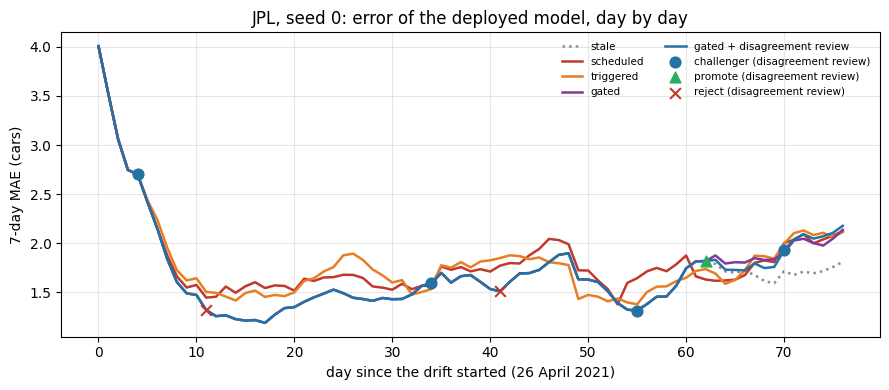

In [11]:
COLORS = {"stale": "#8c8c8c", "scheduled": "#c0392b", "triggered": "#e67e22", "gated": "#7d3c98",
          "gated + disagreement review": "#2471a3"}
seed0 = SEEDS[0]
fig, ax = plt.subplots(figsize=(9, 4))
for setup, color in COLORS.items():
    g = logs[(logs["setup"] == setup) & (logs["seed"] == seed0)].sort_values("day")
    roll = g["err"].rolling(7, min_periods=1).sum() / g["n"].rolling(7, min_periods=1).sum()
    ax.plot(g["day"], roll, color=color, lw=1.8, ls=":" if setup == "stale" else "-", label=setup)
ev = events[(events["setup"] == "gated + disagreement review") & (events["seed"] == seed0)]
g = logs[(logs["setup"] == "gated + disagreement review") & (logs["seed"] == seed0)].sort_values("day")
roll = (g["err"].rolling(7, min_periods=1).sum() / g["n"].rolling(7, min_periods=1).sum()).to_numpy()
for kind, marker, color in [("challenger", "o", "#2471a3"), ("promote", "^", "#27ae60"), ("reject", "x", "#c0392b"),
                            ("alert dismissed", "s", "#f39c12")]:
    days = ev.loc[ev["event"] == kind, "day"].to_numpy(dtype=int)
    if len(days):
        ax.scatter(days, roll[days], marker=marker, s=60, color=color, zorder=5, label=f"{kind} (disagreement review)")
ax.set_xlabel("day since the drift started (26 April 2021)")
ax.set_ylabel("7-day MAE (cars)")
ax.set_title(f"JPL, seed {seed0}: error of the deployed model, day by day")
ax.grid(alpha=0.3)
ax.legend(fontsize=7.5, ncol=2, frameon=False)
fig.tight_layout()
fig.savefig(f"{OUT}/mae_per_day_{SITE}.png", dpi=160)
plt.show()

### Before and after each update

Every promote / reject decision of the main setup (gated + disagreement review), all seeds: both models on the shadow
week (what the gate saw), then both on the following week (what happened next). `correct` = the decision agrees with
the hindsight check over the next 4 weeks.

In [12]:
dec = events[(events["setup"] == "gated + disagreement review") & events["event"].isin(["promote", "reject"])].copy()
dec["date"] = [f"{(timestamps[ONSET] + pd.Timedelta(days=int(dd))).tz_convert(TZ):%d %b}" for dd in dec["day"]]
dec[["seed", "date", "reason", "event", "champion MAE (shadow)", "challenger MAE (shadow)", "MAE next week, champion",
     "MAE next week, challenger", "correct"]].round(3).reset_index(drop=True)

,seed,date,reason,event,champion MAE (shadow),challenger MAE (shadow),"MAE next week, champion","MAE next week, challenger",correct
0,0,06 May,degradation,reject,1.120,1.304,1.272,1.422,True
1,0,05 Jun,accuracy SLO,reject,1.423,1.533,1.897,1.796,False
2,0,26 Jun,age,promote,1.798,1.524,1.592,1.758,False
3,1,06 May,degradation,reject,1.315,1.498,1.312,1.438,True
4,1,18 Jun,degradation,reject,1.337,1.494,1.806,1.720,True
5,1,03 Jul,degradation+age,reject,1.804,2.033,1.970,2.155,NaN
6,2,06 May,degradation,reject,1.278,1.524,1.261,1.452,True
7,2,19 Jun,degradation,reject,1.453,1.578,1.771,1.703,True
8,2,04 Jul,degradation+age,reject,1.812,2.109,1.804,1.994,NaN


## 10. Results: human in the loop and active learning (Q2.4)

The four gated setups differ only in what the operator does. **Reviewed / shadow week**: forecasts the operator looked
at per shadow week; **abnormal found**: share of reviewed forecasts that really touched an abnormal day; **operator
h/week**: alert checks (10 min), reviews (3 min each) and sign-offs (10 min).

In [13]:
gated = events[(events["policy"] == "gated") & events["event"].isin(["promote", "reject"])]
hitl = gated.groupby("setup").agg(shadow_weeks=("event", "size"), reviewed=("reviewed", "sum"),
                                 abnormal=("abnormal reviewed", "sum"), select_ms=("select_ms", "mean"))
hitl["reviewed / shadow week"] = hitl["reviewed"] / hitl["shadow_weeks"]
hitl["abnormal found (%)"] = 100 * hitl["abnormal"] / hitl["reviewed"].replace(0, np.nan)
ok = gated[gated["correct"].notna()].groupby("setup")["correct"]
hitl["right decisions (%)"] = 100 * ok.apply(lambda c: c.astype(bool).mean())
hitl["MAE"] = table["MAE"]
hitl["alerts dismissed"] = table["dismissed"]
hitl["operator h/week"] = effort.groupby("setup")["operator minutes"].mean() / 60 / (REPLAY_DAYS / 7)
hitl = hitl.reindex([s for s in ORDER if s.startswith("gated")])
hitl[["reviewed / shadow week", "abnormal found (%)", "right decisions (%)", "alerts dismissed", "MAE",
      "operator h/week", "select_ms"]].round(2).fillna("–")

,reviewed / shadow week,abnormal found (%),right decisions (%),alerts dismissed,MAE,operator h/week,select_ms
setup,,,,,,,
gated,0.0,–,71.43,0.00,1.61,0.00,–
gated + random review,14.0,11.9,71.43,0.00,1.61,0.29,0.03
gated + disagreement review,14.0,14.29,71.43,0.00,1.61,0.29,0.06
gated + review all,672.0,9.19,57.14,0.33,1.63,9.97,0.01


* **Disagreement sampling enriches anomaly detection:** Only 5 days in 11 weeks are abnormal (9.19% of shadow
  windows). Reviewing the 2 windows with the largest model disagreement finds an abnormal window 14.29% of the time,
  against 11.90% for random review (1.55x over the base rate).
* **Minimal effect on promotion outcomes:** With 14 reviews per shadow week, `gated + random` and
  `gated + disagreement` make the exact same decisions as `gated` with no human (5 of 7 right, 71.43%) and achieve
  virtually identical error (MAE 1.612 - 1.614).
* **Exhaustive review (`review all`) hurts accuracy and efficiency:** Reviewing all 672 windows per shadow week with a
  5% operator tagging error injects ~34 false-positive window quarantines per week, shrinking clean evaluation data,
  dropping hindsight accuracy to 4 of 7 (57.14%), increasing MAE to 1.629, and costing 9.97 operator-hours per week.
* **Cost:** 0.29 operator-hours per week (~17 min/week) for 14 reviews and sign-offs; disagreement selection takes
  0.06 ms per day.

## 11. Cost of the updates

* **training**: one challenger (DLinear + Ridge + stacking + CQR) on CPU; **peak RSS**: process memory after training.
* **shadow cost**: the challenger forecasts every 15 minutes next to the champion, so inference doubles during a shadow
  week (measured per forecast, in batch).
* **decision delay**: days from the retrain alert to the promotion.

In [14]:
trained = events[events["event"].isin(["challenger", "deploy"])]
cost = pd.DataFrame({
    "training time (s)": trained["train_s"].describe()[["mean", "min", "max"]],
    "peak RSS (MiB)": trained["rss_mib"].describe()[["mean", "min", "max"]],
}).T
cost["mean"] = cost["mean"].round(2)
print(cost.round(2).to_string())
print(f"\ninference per forecast (batch, one model): {start_models[SEEDS[0]]['infer_ms'] * 1000:.1f} us; "
      f"doubled during a shadow week")
print(f"decision delay: {SHADOW_DAYS} days of shadow after each alert (plus the 1-day training slot)")

                      mean      min      max
training time (s)    23.43    12.18    43.12
peak RSS (MiB)     2495.09  2465.46  2554.19

inference per forecast (batch, one model): 20.0 us; doubled during a shadow week
decision delay: 7 days of shadow after each alert (plus the 1-day training slot)


## 12. Summary

* **No retraining wins under this drift:** `stale` achieves the lowest error (MAE 1.596, coverage 0.811) because
  DLinear's 7-day lookback window absorbs the 2.5-hour Time-of-Use shift after one week and daily Split-CQR
  recalibration maintains interval coverage.
* **Ungated updates hurt performance:** `triggered` (MAE 1.734, 4.7 deploys) and `scheduled` (MAE 1.760, 11 deploys)
  overfit recent fluctuations under a 14-day recency half-life and deploy models worse than `v0`.
* **Champion-challenger gating acts as an effective safety filter:** Gating rejects 80% of challengers (5 of 7
  decisions right, 71.4%), keeping MAE at 1.612 - 1.614 (within 1% of `stale`).
* **Human review enriches anomaly detection at low cost, while exhaustive review backfires:** Disagreement sampling
  finds abnormal windows at 14.29% (vs 11.90% random and 9.19% base rate) for 0.29 operator-hours/week, whereas
  `review all` (9.97 h/week) degrades decisions to 4 of 7 (MAE 1.629) due to 5% false-positive quarantine noise.
* **When the gate and the human matter most:** When drift is structural rather than absorbed by the lookback window,
  or when severe data corruption reaches training and causes challengers to fail clearly against the champion.

**Files in `outputs/continual/`:** `daily_jpl.csv` (every policy, seed and day), `events_jpl.csv` (every alert,
challenger, recalibration and decision), `effort_jpl.csv` (operator time), `summary_jpl.csv` (the Q1.4 table) and
`mae_per_day_jpl.png`.